# Лабораторная работа №1 — Визуализация данных

Датасет: Wine Quality (red + white). Ноутбук скачивает CSV, объединяет наборы и выполняет EDA, очистку, преобразования и визуализации (PCA, t-SNE, UMAP, MDS) в соответствии с заданием. Запустите все ячейки по порядку.

In [57]:
# При необходимости установите зависимости (раскомментируйте и выполните один раз)
# import sys
# !{sys.executable} -m pip install pandas numpy scikit-learn seaborn matplotlib umap-learn requests
print( ( (8-1) % 7 ) + 1 ) 

1


In [27]:
import os
import io
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, MDS
try:
    import umap
    UMAP_AVAILABLE = True
except Exception:
    UMAP_AVAILABLE = False

sns.set(style="whitegrid")

In [28]:
# Ссылки на CSV-файлы (UCI)
urls = {
    'red': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'white': 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
}
os.makedirs('data', exist_ok=True)
for k, url in urls.items():
    path = os.path.join('data', f'winequality-{k}.csv')
    if not os.path.exists(path):
        print(f'Downloading {k}...')
        r = requests.get(url)
        r.raise_for_status()
        # Файлы разделены точкой с запятой
        with open(path, 'wb') as f:
            f.write(r.content)
    else:
        print(f'Found {path}')

Found data\winequality-red.csv
Found data\winequality-white.csv


In [29]:
# Загрузка CSV как DataFrame
df_red = pd.read_csv('data/winequality-red.csv', sep=';')
df_white = pd.read_csv('data/winequality-white.csv', sep=';')
df_red['type'] = 'red'
df_white['type'] = 'white'
df = pd.concat([df_red, df_white], ignore_index=True)
print('Shape:', df.shape)
df.head()

Shape: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [30]:
# Быстрое исследование
display(df.info())
display(df.describe())
display(df['quality'].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


None

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

In [31]:
# 1) Очистка данных: пропуски и выбросы
# Проверим пропуски
print('Missing values:', df.isnull().sum())

# Простая детекция выбросов методом IQR для числовых колонок
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
def remove_outliers_iqr(df_, cols):
    df = df_.copy()
    for c in cols:
        Q1 = df[c].quantile(0.25)
        Q3 = df[c].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df = df[(df[c] >= lower) & (df[c] <= upper)]
    return df
df_no_outliers = remove_outliers_iqr(df, num_cols)
print('Before:', df.shape, 'After removing outliers:', df_no_outliers.shape)

Missing values: fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64
Before: (6497, 13) After removing outliers: (4418, 13)


In [32]:
# 2) Преобразование признаков: масштабирование и кодирование
X = df_no_outliers.drop(columns=['quality', 'type'])
y = df_no_outliers['quality']
type_col = df_no_outliers['type']
# Кодирование типа как бинарная переменная
X = X.copy()
X['is_red'] = (type_col == 'red').astype(int)
# Масштабирование
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

print('Features shape:', X.shape)
X_scaled.head()

Features shape: (4418, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
20,2.384097,-0.632939,1.767431,-0.870701,2.544862,-0.262219,-1.495325,0.975829,1.325386,0.329527,-0.963373,3.398696
25,-0.737006,1.052908,-1.768982,-0.954765,2.781730,-1.428671,-2.281962,0.512402,0.976005,0.608016,-1.047372,3.398696
26,0.823546,1.251243,-0.884879,-0.870701,2.781730,-1.882291,-2.537087,0.761939,0.556748,0.886505,-0.879373,3.398696
33,-0.016751,3.185009,-2.211033,0.999712,2.229037,0.450613,-1.006335,1.867035,1.744643,0.236697,-0.963373,3.398696
37,1.423758,0.953741,-0.442827,-0.807653,1.676344,-1.299065,-2.133139,0.975829,0.207367,2.186122,-0.711373,3.398696


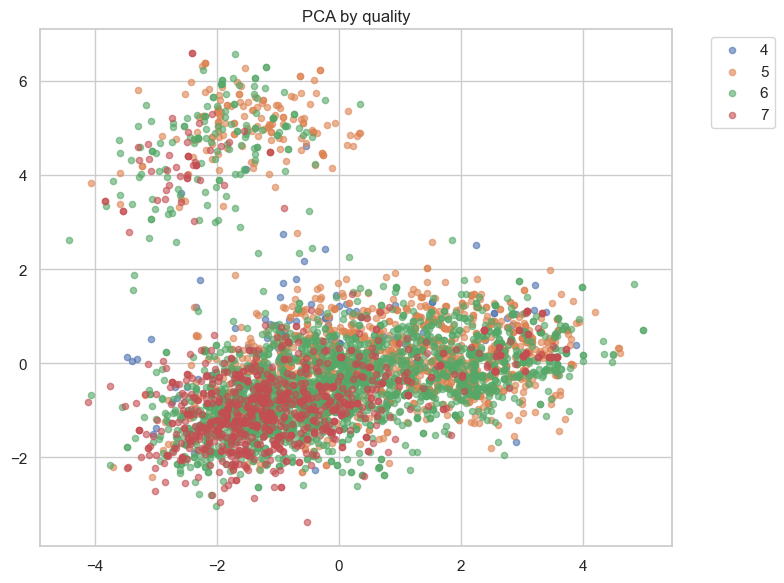

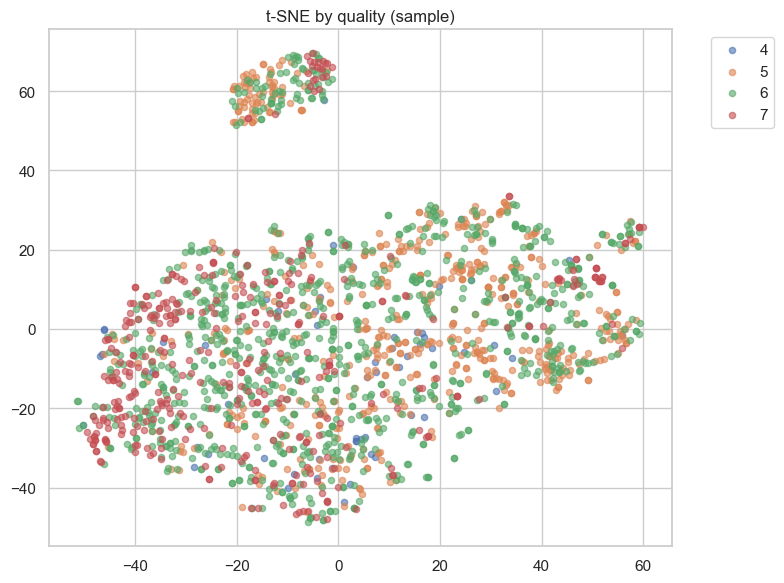

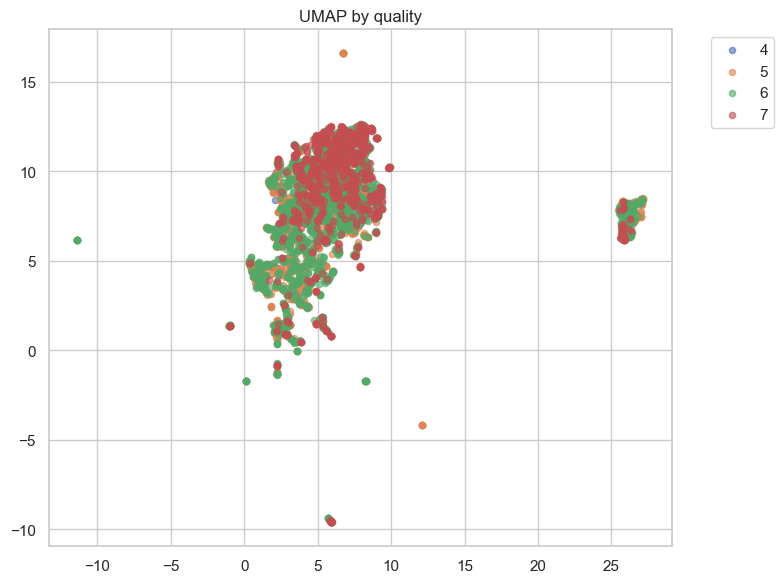

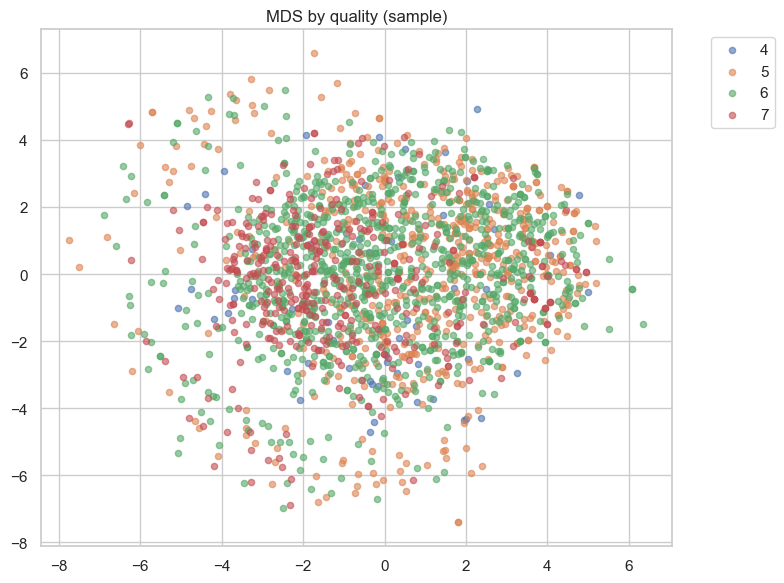

In [33]:
# 3) Снижение размерности и визуализация
def plot_2d(df_emb, labels, title):
    plt.figure(figsize=(8,6))
    unique = np.unique(labels)
    for u in unique:
        mask = labels == u
        plt.scatter(df_emb[mask,0], df_emb[mask,1], label=str(u), alpha=0.6, s=20)
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# PCA
pca = PCA(n_components=2, random_state=42)
emb_pca = pca.fit_transform(X_scaled)
plot_2d(emb_pca, y.values, 'PCA by quality')

# t-SNE (на подвыборке для скорости)
sample_idx = np.random.RandomState(42).choice(len(X_scaled), size=min(2000, len(X_scaled)), replace=False)
tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto')
emb_tsne = tsne.fit_transform(X_scaled.iloc[sample_idx])
plot_2d(emb_tsne, y.iloc[sample_idx].values, 't-SNE by quality (sample)')

# UMAP если доступен
if UMAP_AVAILABLE:
    reducer = umap.UMAP(n_components=2, random_state=42, n_jobs=1)
    emb_umap = reducer.fit_transform(X_scaled)
    plot_2d(emb_umap, y.values, 'UMAP by quality')
else:
    print('UMAP не установлен — пропускаю.')

# MDS (на подвыборке)
mds = MDS(n_components=2, random_state=42, n_jobs=1, n_init=1)
emb_mds = mds.fit_transform(X_scaled.iloc[sample_idx])
plot_2d(emb_mds, y.iloc[sample_idx].values, 'MDS by quality (sample)')

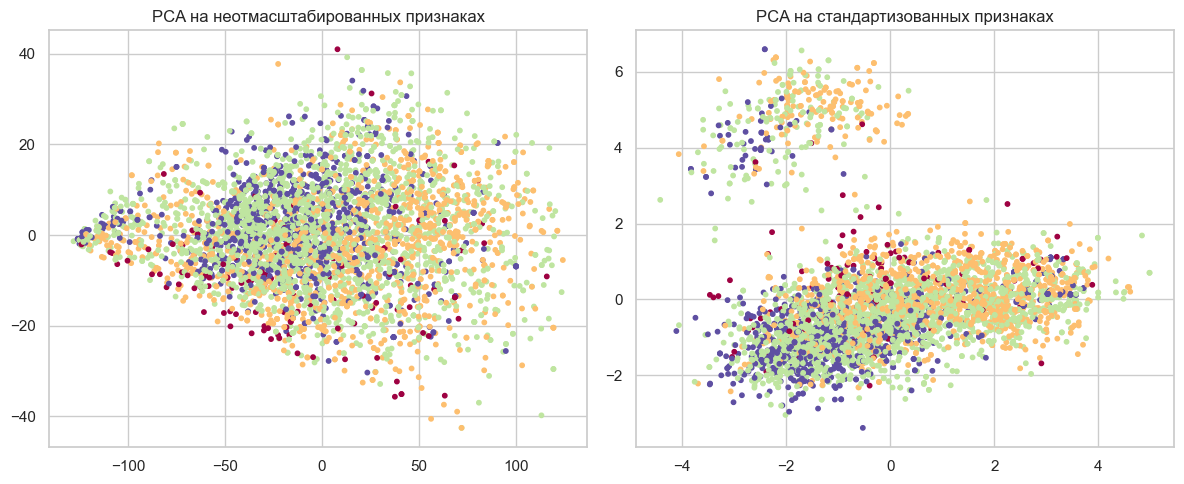

In [34]:
# 4) Сравнение до/после преобразований (пример на PCA)
pca_raw = PCA(n_components=2, random_state=42)
emb_raw = pca_raw.fit_transform(X)
emb_scaled = pca.transform(X_scaled)
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.scatter(emb_raw[:,0], emb_raw[:,1], c=y.values, cmap='Spectral', s=10)
plt.title('PCA на неотмасштабированных признаках')
plt.subplot(1,2,2)
plt.scatter(emb_scaled[:,0], emb_scaled[:,1], c=y.values, cmap='Spectral', s=10)
plt.title('PCA на стандартизованных признаках')
plt.tight_layout()
plt.show()

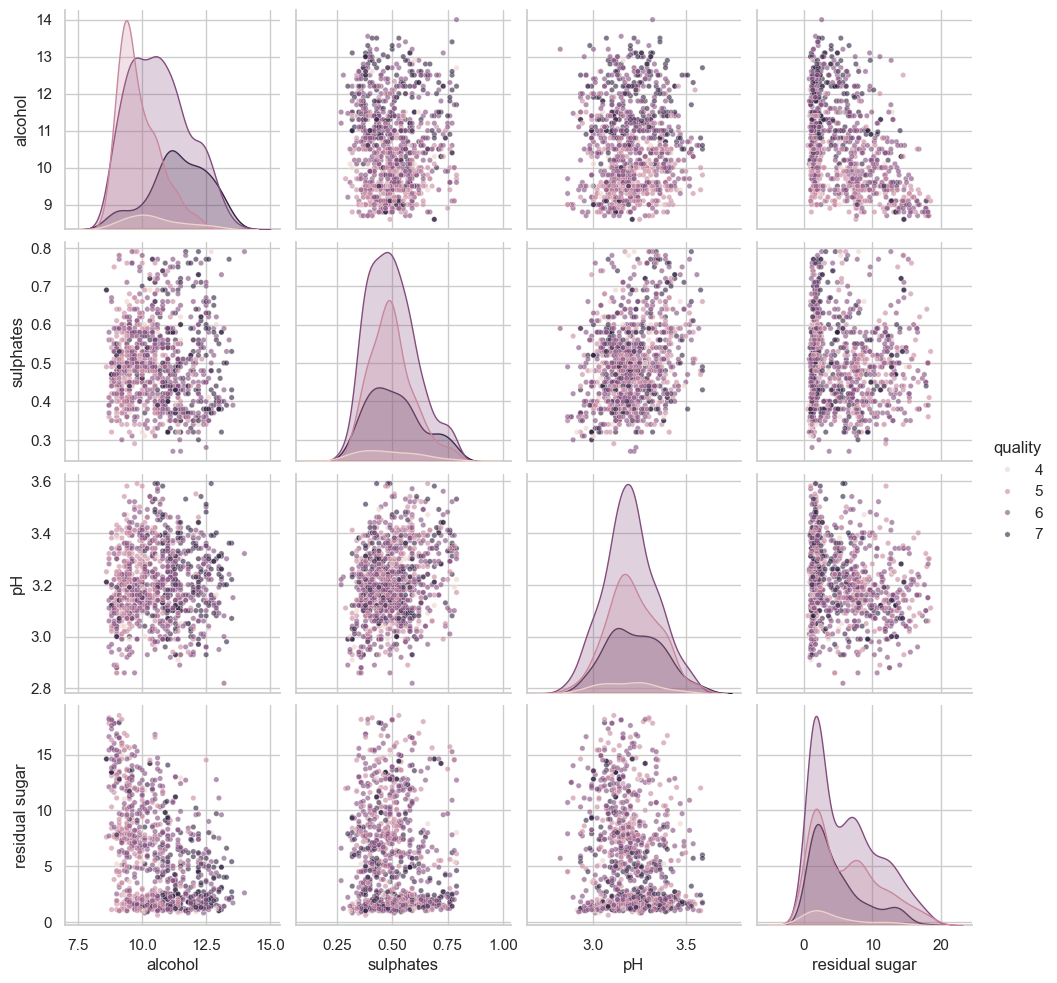

In [35]:
# 5) Визуализация без снижения размерности: pairplot для выбранных признаков
sample = df_no_outliers.sample(n=min(1000, len(df_no_outliers)), random_state=42)
cols_for_pair = ['alcohol', 'sulphates', 'pH', 'residual sugar', 'quality']
sns.pairplot(sample[cols_for_pair], hue='quality', plot_kws={'s':15, 'alpha':0.6})
plt.show()

## Выводы и дальнейшие шаги
- В ноутбуке выполнены: загрузка, объединение наборов, простая очистка, масштабирование, снижение размерности и визуализация.
- Для отчёта можно добавить метрики кластеризации / более глубокий анализ выбросов и влияние категориальных признаков.